# Wind Event in June, 2023

This notebook inspects the wind event in June, 2023. 

## Setup

### Weight files

Forcing field -- weight files --> interpolated wind speed. Weight files help to link ocean model grids with atmospheric grids.

In [8]:
# paths of weight files

path_weight_CaSR='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-CaSR_202108.nc'
path_weight_HRDPS25='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-continental2.5-hrdps.nc'
path_weight_HRDPS1='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-1km_202108.nc'
path_weight_HRDPS10='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-subsampled_202108.nc'

In [2]:
# show info

import xarray as xr

ds_weight_CaSR=xr.load_dataset(path_weight_CaSR)
print(ds_weight_CaSR)

<xarray.Dataset> Size: 23MB
Dimensions:  (lat: 105, lon: 70, y: 898, x: 398)
Dimensions without coordinates: lat, lon, y, x
Data variables:
    nav_lat  (lat, lon) float64 59kB 43.38 43.42 43.46 43.5 ... 54.42 54.46 54.5
    nav_lon  (lat, lon) float64 59kB 235.9 236.0 236.1 ... 237.9 238.0 238.2
    src01    (y, x) int64 3MB 2263 2263 2264 2264 2264 ... 5428 5428 5428 5429
    wgt01    (y, x) float64 3MB 0.4846 0.4456 0.4309 ... 0.3529 0.3283 0.3437
    src02    (y, x) int64 3MB 2333 2333 2334 2334 2334 ... 5498 5498 5498 5499
    wgt02    (y, x) float64 3MB 0.09251 0.08566 0.08339 ... 0.1897 0.1774 0.1867
    src03    (y, x) int64 3MB 2264 2264 2263 2263 2263 ... 5429 5429 5429 5428
    wgt03    (y, x) float64 3MB 0.3551 0.3931 0.407 ... 0.2975 0.3209 0.3043
    src04    (y, x) int64 3MB 2334 2334 2333 2333 2333 ... 5499 5499 5499 5498
    wgt04    (y, x) float64 3MB 0.0678 0.07557 0.07876 ... 0.1599 0.1734 0.1653
Attributes:
    Conventions:  CF-1.6
    title:        SalishSeaCast N

`y` and `x` has the size of the NEMO grid. For each NEMO grid point, it uses `src` to find the number of 4 source points in the forcing field. One number represents a grid point in atmospheric forcing field, using `flat_index = ilat*nlon + ilon`, all of which are indexes. `wgt` represents the weight for the variable.

### Size of all forcing fields

In [1]:
example_path_CaSR='/ocean/jqiu/forcings/CaSR/CaSR_y2023m03d01.nc'
example_path_HRDPS25='/results/forcing/atmospheric/continental2.5/nemo_forcing/hrdps_y2023m03d01.nc'
example_path_HRDPS10='/ocean/jqiu/forcings/HRDPS_subsampled/hrdps_subsampled_y2023m03d01.nc'
example_path_HRDPS1='/ocean/jqiu/forcings/HRDPS_1km/HRDPS_1km_y2023m03d01.nc'

In [2]:
import xarray as xr

example_ds_CaSR=xr.open_dataset(example_path_CaSR)
example_ds_HRDPS25=xr.open_dataset(example_path_HRDPS25)
example_ds_HRDPS1=xr.open_dataset(example_path_HRDPS1)
example_ds_HRDPS10=xr.open_dataset(example_path_HRDPS10)



In [3]:
# size of CaSR

print(example_ds_CaSR)


<xarray.Dataset> Size: 6MB
Dimensions:       (time_counter: 24, y: 105, x: 70)
Coordinates:
  * time_counter  (time_counter) datetime64[ns] 192B 2023-03-01 ... 2023-03-0...
  * y             (y) int32 420B 0 1 2 3 4 5 6 7 ... 98 99 100 101 102 103 104
  * x             (x) int32 280B 0 1 2 3 4 5 6 7 8 ... 62 63 64 65 66 67 68 69
    nav_lat       (y, x) float32 29kB ...
    nav_lon       (y, x) float32 29kB ...
Data variables:
    solar         (time_counter, y, x) float32 706kB ...
    precip        (time_counter, y, x) float32 706kB ...
    therm_rad     (time_counter, y, x) float32 706kB ...
    tair          (time_counter, y, x) float32 706kB ...
    qair          (time_counter, y, x) float32 706kB ...
    u_wind        (time_counter, y, x) float32 706kB ...
    atmpres       (time_counter, y, x) float32 706kB ...
    v_wind        (time_counter, y, x) float32 706kB ...
    percentcloud  (time_counter, y, x) float32 706kB ...
Attributes:
    title:           Converted CaSR atmosphe

In [4]:
# size of HRDPS 2.5

print(example_ds_HRDPS25)


<xarray.Dataset> Size: 55MB
Dimensions:           (time_counter: 24, y: 230, x: 190)
Coordinates:
  * y                 (y) int64 2kB 0 1 2 3 4 5 6 ... 224 225 226 227 228 229
  * x                 (x) int64 2kB 0 1 2 3 4 5 6 ... 184 185 186 187 188 189
  * time_counter      (time_counter) datetime64[ns] 192B 2023-03-01 ... 2023-...
    nav_lon           (y, x) float64 350kB ...
    nav_lat           (y, x) float64 350kB ...
Data variables:
    LHTFL_surface     (time_counter, y, x) float32 4MB ...
    PRATE_surface     (time_counter, y, x) float32 4MB ...
    RH_2maboveground  (time_counter, y, x) float32 4MB ...
    atmpres           (time_counter, y, x) float32 4MB ...
    precip            (time_counter, y, x) float32 4MB ...
    qair              (time_counter, y, x) float32 4MB ...
    solar             (time_counter, y, x) float32 4MB ...
    tair              (time_counter, y, x) float32 4MB ...
    therm_rad         (time_counter, y, x) float32 4MB ...
    u_wind            (t

In [5]:
# size of HRDPS 1

print(example_ds_HRDPS1)


<xarray.Dataset> Size: 1GB
Dimensions:       (time_counter: 24, y: 1180, x: 1330)
Coordinates:
  * time_counter  (time_counter) datetime64[ns] 192B 2023-03-01 ... 2023-03-0...
  * y             (y) int32 5kB 0 1 2 3 4 5 6 ... 1174 1175 1176 1177 1178 1179
  * x             (x) int32 5kB 0 1 2 3 4 5 6 ... 1324 1325 1326 1327 1328 1329
    nav_lat       (y, x) float64 13MB ...
    nav_lon       (y, x) float64 13MB ...
Data variables:
    solar         (time_counter, y, x) float32 151MB ...
    precip        (time_counter, y, x) float32 151MB ...
    therm_rad     (time_counter, y, x) float32 151MB ...
    tair          (time_counter, y, x) float32 151MB ...
    qair          (time_counter, y, x) float32 151MB ...
    u_wind        (time_counter, y, x) float32 151MB ...
    v_wind        (time_counter, y, x) float32 151MB ...
    atmpres       (time_counter, y, x) float32 151MB ...
    percentcloud  (time_counter, y, x) float32 151MB ...
Attributes: (12/16)
    title:                     

In [6]:
# size of HRDPS 10

print(example_ds_HRDPS10)

<xarray.Dataset> Size: 4MB
Dimensions:           (time_counter: 24, y: 58, x: 48)
Coordinates:
  * y                 (y) int64 464B 0 4 8 12 16 20 ... 208 212 216 220 224 228
  * x                 (x) int64 384B 0 4 8 12 16 20 ... 168 172 176 180 184 188
  * time_counter      (time_counter) datetime64[ns] 192B 2023-03-01 ... 2023-...
    nav_lon           (y, x) float64 22kB ...
    nav_lat           (y, x) float64 22kB ...
Data variables:
    LHTFL_surface     (time_counter, y, x) float32 267kB ...
    PRATE_surface     (time_counter, y, x) float32 267kB ...
    RH_2maboveground  (time_counter, y, x) float32 267kB ...
    atmpres           (time_counter, y, x) float32 267kB ...
    precip            (time_counter, y, x) float32 267kB ...
    qair              (time_counter, y, x) float32 267kB ...
    solar             (time_counter, y, x) float32 267kB ...
    tair              (time_counter, y, x) float32 267kB ...
    therm_rad         (time_counter, y, x) float32 267kB ...
    u_w

### Regions



In [7]:
# Grid Regions
REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

## Wind in June at Pam Rocks



In [17]:
from pathlib import Path
import calendar
from datetime import date
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

YEAR = 2023
MONTH = 6
REGION_NAME = "SandHeads"
PROJECTION_SIGN = 1  # 1: towards NW; -1: wind from NW (towards SE)
OUTPUT_DIR = '/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_atmo_events/Jun_2023/Data_June_Sandheads/'
# When False, missing daily forcing files raise an error; True logs and skips them.
SKIP_MISSING_FILES = False

REGIONS = {
    "Central SoG":  (450, 500, 250, 300),
    "Juan de Fuca": (300, 365,  50, 100),
    "Haro Strait":  (280, 320, 210, 250),
    "Northern SoG": (650, 700, 140, 180),
    "Puget Sound":  (75,  125, 225, 280),
    "Pam Rocks":    (490, 510, 330, 350),
    "SandHeads":    (420, 440, 280, 300),
}

# Atmospheric *source* grid (y, x) shapes, daily file patterns and weights.
FORCINGS = {
    "CaSR": {
        "shape": (105, 70),
        "file_pattern": "/ocean/jqiu/forcings/CaSR/CaSR_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-CaSR_202108.nc",
    },
    "HRDPS25": {
        "shape": (230, 190),
        "file_pattern": "/results/forcing/atmospheric/continental2.5/nemo_forcing/hrdps_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-continental2.5-hrdps.nc",
    },
    "HRDPS1": {
        "shape": (1180, 1330),
        "file_pattern": "/ocean/jqiu/forcings/HRDPS_1km/HRDPS_1km_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-1km_202108.nc",
    },
    "HRDPS10": {
        "shape": (58, 48),
        "file_pattern": "/ocean/jqiu/forcings/HRDPS_subsampled/hrdps_subsampled_y{year}m{month:02d}d{day:02d}.nc",
        "weights": "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-HRDPS-subsampled_202108.nc",
    },
}

j0, j1, i0, i1 = REGIONS[REGION_NAME]
assert 0 <= j0 < j1 and 0 <= i0 < i1
region_slices = {"y": slice(j0, j1), "x": slice(i0, i1)}
n_region_points = (j1 - j0) * (i1 - i0)


print(f"{REGION_NAME}: j=[{j0}:{j1}), i=[{i0}:{i1}); {n_region_points} ocean points")

SandHeads: j=[420:440), i=[280:300); 400 ocean points


In [18]:
def load_region_weights(path, target_slices, forcing_shape):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Missing weights file: {path}")
    with xr.open_dataset(path) as ds:
        for k in range(1, 5):
            for prefix in ("src", "wgt"):
                var = f"{prefix}0{k}"
                if var not in ds:
                    raise KeyError(f"{var} is missing from {path}")
        # Ensure the entire region exists in the NEMO target grid.
        if ds.sizes["y"] < target_slices["y"].stop or ds.sizes["x"] < target_slices["x"].stop:
            raise ValueError(f"Region lies outside target grid in {path}")
        source = np.stack([
            ds[f"src0{k}"].isel(**target_slices).transpose("y", "x").values
            for k in range(1, 5)
        ]).reshape(4, -1)
        weights = np.stack([
            ds[f"wgt0{k}"].isel(**target_slices).transpose("y", "x").values
            for k in range(1, 5)
        ]).reshape(4, -1).astype(float)


    source = source.astype(np.int64) - 1
 
    n_source = np.prod(forcing_shape)
    invalid = (source < 0) | (source >= n_source)

    
    weights = np.where(invalid, 0.0, weights)
    source = np.where(invalid, 0, source)


    return source, weights

region_weights = {}
for forcing, config in FORCINGS.items():
    src, wgt = load_region_weights(config["weights"], region_slices, config["shape"])
    assert src.shape == (4, n_region_points)
    region_weights[forcing] = (src, wgt)
    print(f"{forcing}: {src.shape[1]} target ocean cells, weights loaded")



CaSR: 400 target ocean cells, weights loaded
HRDPS25: 400 target ocean cells, weights loaded
HRDPS1: 400 target ocean cells, weights loaded
HRDPS10: 400 target ocean cells, weights loaded


In [19]:
def timestamp_string(value):
    if isinstance(value, np.datetime64):
        return np.datetime_as_string(value, unit="s")
    if hasattr(value, "strftime"):
        return value.strftime("%Y-%m-%dT%H:%M:%S")
    raise ValueError(f"Unsupported timestamp: {value!r}")


def process_daily_file(path, source_shape, source_index, weights, expected_date):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(path)
    records = []
    with xr.open_dataset(path) as ds:
        for var_name in ("u_wind", "v_wind"):
            if var_name not in ds:
                raise KeyError(f"{var_name} not found in {path}")
            var = ds[var_name]
            if not {"time_counter", "y", "x"}.issubset(var.dims):
                raise ValueError(f"Unexpected dims for {var_name}: {var.dims}")
            if (var.sizes["y"], var.sizes["x"]) != source_shape:
                raise ValueError(f"{var_name} grid shape mismatch in {path}")
        if "time_counter" not in ds.coords:
            raise ValueError(f"Missing time_counter coordinate: {path}")
        times = ds["time_counter"].values
        for t, time_value in enumerate(times):
            timestamp = timestamp_string(time_value)
            if timestamp[:10] != expected_date.isoformat():
                raise ValueError(f"Unexpected timestamp {timestamp} in {path}")
            u = ds["u_wind"].isel(time_counter=t).transpose("y", "x").values.ravel()
            v = ds["v_wind"].isel(time_counter=t).transpose("y", "x").values.ravel()
            u_neighbors = u[source_index]
            v_neighbors = v[source_index]
            used = np.abs(weights) > 0
            valid = np.all(~used | (np.isfinite(u_neighbors) & np.isfinite(v_neighbors)), axis=0)
            u_grid = np.sum(np.where(used, u_neighbors, 0.0) * weights, axis=0)
            v_grid = np.sum(np.where(used, v_neighbors, 0.0) * weights, axis=0)
            nw_grid = PROJECTION_SIGN * (v_grid - u_grid) / np.sqrt(2.0)
            nw_grid[~valid] = np.nan
            n_valid = int(np.isfinite(nw_grid).sum())
            records.append({
                "time": timestamp,
                "nw45_wind_ms": float(np.nanmean(nw_grid)) if n_valid else np.nan,
                "n_valid": n_valid,
            })
    return records



In [20]:
# extract
results = []
missing_files = []
n_days = calendar.monthrange(YEAR, MONTH)[1]

for forcing, config in FORCINGS.items():
    src, wgt = region_weights[forcing]
    count = 0
    for day in range(1, n_days + 1):
        this_date = date(YEAR, MONTH, day)
        daily_path = config["file_pattern"].format(year=YEAR, month=MONTH, day=day)
        if not Path(daily_path).is_file():
            if not SKIP_MISSING_FILES:
                raise FileNotFoundError(daily_path)
            missing_files.append(daily_path)
            continue
        daily_records = process_daily_file(daily_path, config["shape"], src, wgt, this_date)
        for record in daily_records:
            record.update({"forcing": forcing, "region": REGION_NAME, "n_region_points": n_region_points})
        results.extend(daily_records)
        count += len(daily_records)
    print(f"{forcing}: {count} time records processed")

if not results:
    raise RuntimeError("No forcing records were processed. Check paths and selected year/month.")

df_long = pd.DataFrame(results).sort_values(["time", "forcing"]).reset_index(drop=True)
df_long["time"] = pd.to_datetime(df_long["time"])
df_wide = df_long.pivot(index="time", columns="forcing", values="nw45_wind_ms").reset_index()
df_wide.columns.name = None


CaSR: 720 time records processed
HRDPS25: 720 time records processed
HRDPS1: 720 time records processed
HRDPS10: 720 time records processed


In [21]:

long_path = OUTPUT_DIR + f"{REGION_NAME}_NW45_{YEAR}{MONTH:02d}_long.csv"
wide_path = OUTPUT_DIR + f"{REGION_NAME}_NW45_{YEAR}{MONTH:02d}_wide.csv"
# df_long.to_csv(long_path, index=False)
df_wide.to_csv(wide_path, index=False)
# print(f"Saved long CSV: {long_path}")
print(f"Saved wide CSV: {wide_path}")


Saved wide CSV: /home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_atmo_events/Jun_2023/Data_June_Sandheads/SandHeads_NW45_202306_wide.csv


## Visualization


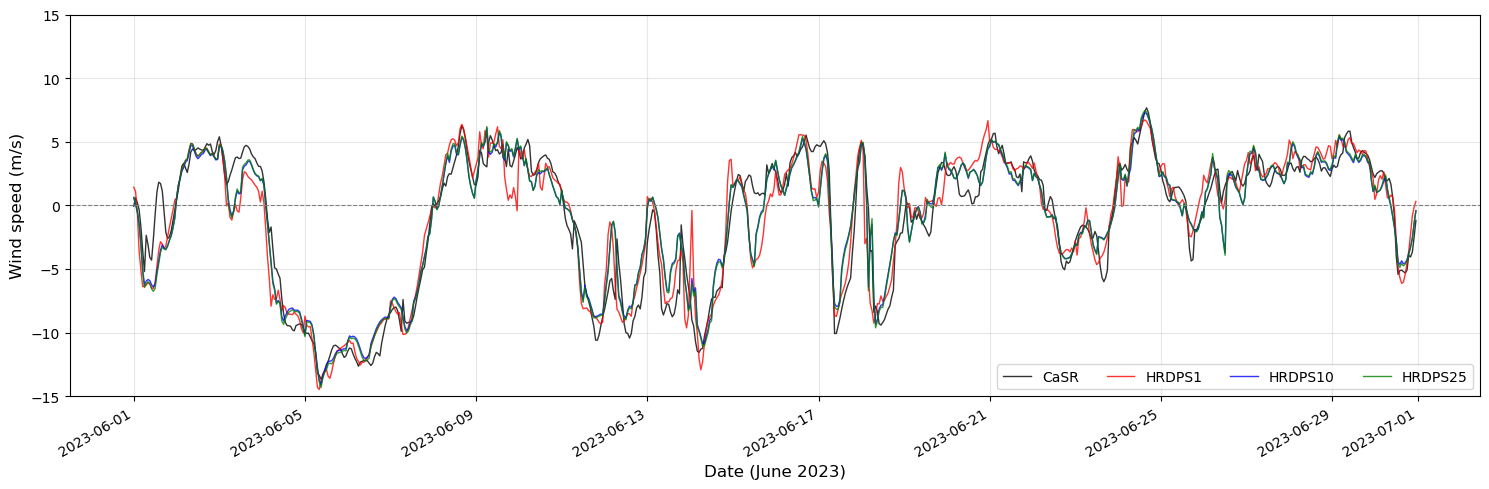

In [25]:

import pandas as pd
import matplotlib.pyplot as plt

# Read CSV

path_wind = '/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_atmo_events/Jun_2023/Data_June_Sandheads/SandHeads_NW45_202306_wide.csv'

df = pd.read_csv(path_wind)

# Clean column names
df.columns = (
    df.columns
    .str.replace('*', '', regex=False)
    .str.replace('&#x48;', 'H', regex=False)
    .str.strip()
)

# Convert time to datetime
df['time'] = pd.to_datetime(df['time'])

# Set time as index
df = df.set_index('time')

# Convert data to numeric (remove * if present)
for col in df.columns:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace('*', '', regex=False),
        errors='coerce'
    )

# Select June 2023
df_june = df.loc['2023-06-01':'2023-06-30']

# visualize
fig, ax = plt.subplots(figsize=(15, 5))

colors = {
    'CaSR': 'black',
    'HRDPS1': 'red',
    'HRDPS10': 'blue',
    'HRDPS25': 'green'
}

for col in colors:
    if col in df_june.columns:
        ax.plot(
            df_june.index,
            df_june[col],
            label=col,
            color=colors[col],
            linewidth=1.0,
            alpha=0.8
        )

ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_ylim(-15,15)
ax.set_xlabel('Date (June 2023)', fontsize=12)
ax.set_ylabel('Wind speed (m/s)', fontsize=12)


ax.legend(loc='lower right', ncol=4)
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

There is a storm blowing towards **Southeast** during June 4 to June 8.

### Scatter Plot

Note: this is the scatter plot of the entire region. 

In [27]:
# paths

path_obs='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_forcing_vs_observation/Data_sandheads_2008_2024/en_climate_hourly_BC_1107010_06-2023_P1H.csv'
path_mod='/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Analysis_atmo_events/Jun_2023/Data_June_Sandheads/SandHeads_NW45_202306_wide.csv'




Daily NW45 wind velocity:
            Observation       CaSR     HRDPS1    HRDPS10    HRDPS25
time                                                               
2023-06-01    -0.841775  -1.364323  -3.456470  -3.589370  -3.710238
2023-06-02     5.518836   3.772230   3.688287   3.573130   3.686462
2023-06-03     5.152245   3.604326   1.359314   2.178785   2.239218
2023-06-04    -5.302141  -6.017049  -6.949845  -6.297008  -6.420300
2023-06-05   -11.598626 -11.630612 -11.892264 -11.533834 -11.696229

DAILY NW45 WIND STATISTICS
          Bias   RMSE      R     N
CaSR    -1.483  1.736  0.986  30.0
HRDPS1  -1.511  1.834  0.982  30.0
HRDPS10 -1.439  1.791  0.987  30.0
HRDPS25 -1.448  1.767  0.987  30.0


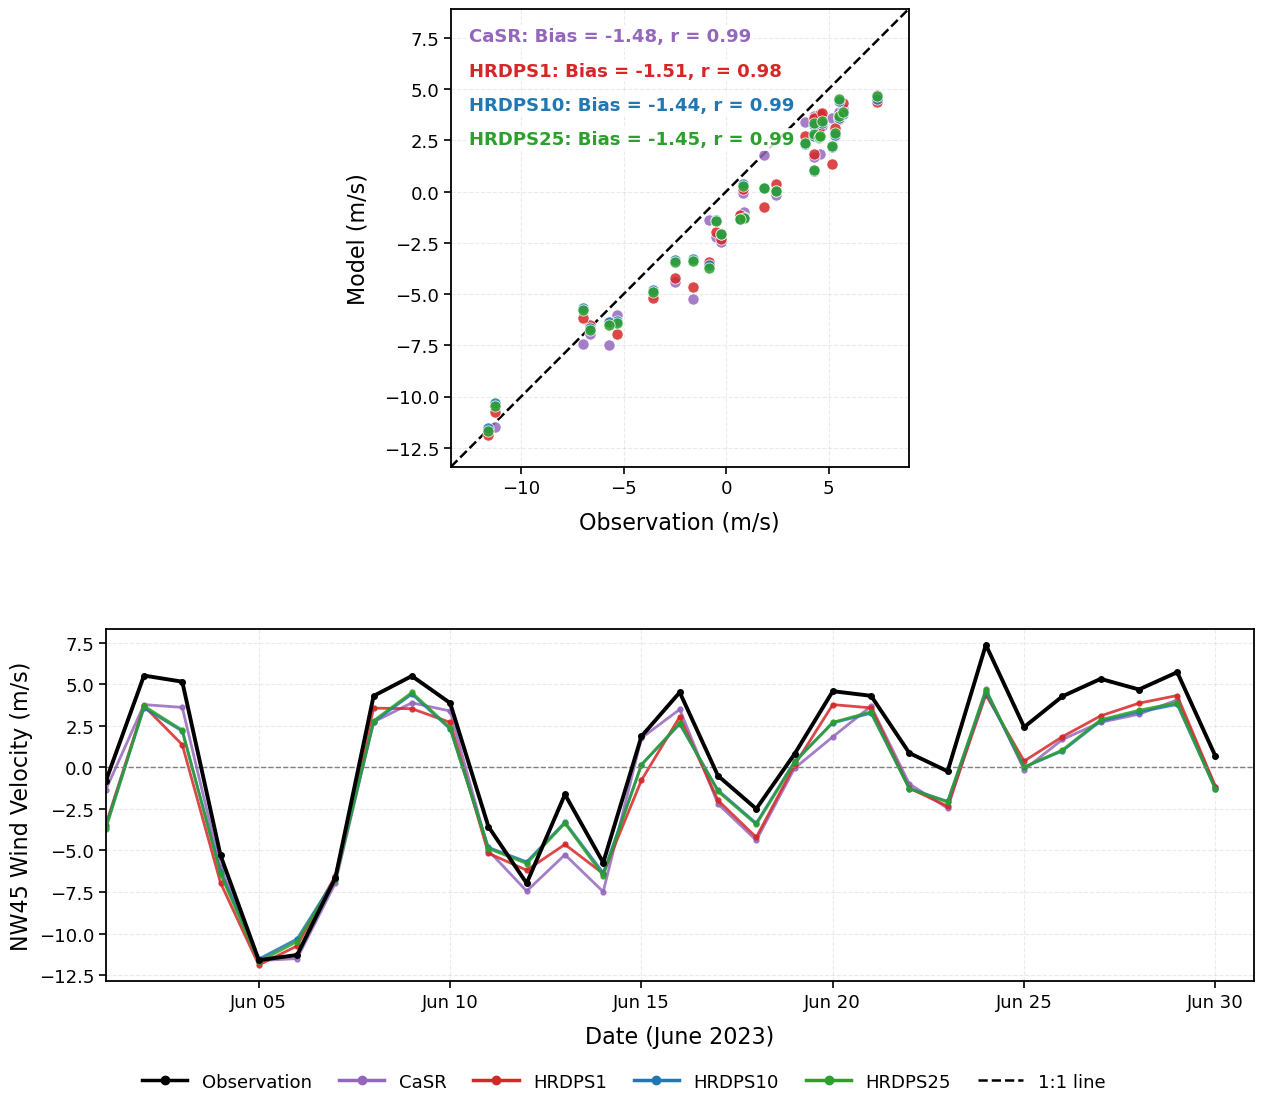

In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D



# Settings


EXPERIMENTS = ['CaSR', 'HRDPS1', 'HRDPS10', 'HRDPS25']

COLORS = {
    'Observation': 'black',
    'CaSR': '#9467bd',
    'HRDPS1': '#d62728',
    'HRDPS10': '#1f77b4',
    'HRDPS25': '#2ca02c'
}

# Positive toward NW (315 degrees)
NW45_ANGLE = 315.0

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 15,
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "axes.labelsize": 17,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 14,
    "axes.linewidth": 1.3,
    "savefig.dpi": 300,
})

# Read obs

obs = pd.read_csv(path_obs, encoding='utf-8-sig')

obs.columns = obs.columns.str.strip()

obs['time'] = pd.to_datetime(
    obs['Date/Time (UTC)'],
    errors='coerce'
)

obs['Wind Spd (km/h)'] = pd.to_numeric(
    obs['Wind Spd (km/h)'],
    errors='coerce'
)

obs['Wind Dir (10s deg)'] = pd.to_numeric(
    obs['Wind Dir (10s deg)'],
    errors='coerce'
)

# Convert km/h to m/s
wind_speed = obs['Wind Spd (km/h)'] / 3.6

# Convert tens of degrees to degrees
wind_dir = obs['Wind Dir (10s deg)'] * 10.0

# Meteorological wind direction is FROM direction.
# Positive projected velocity is TOWARD NW.
obs['NW45'] = -wind_speed * np.cos(
    np.deg2rad(wind_dir - NW45_ANGLE)
)

# Calm wind: direction may be missing, projected speed = 0
obs.loc[
    (wind_speed == 0) & wind_dir.isna(),
    'NW45'
] = 0.0

obs = obs.set_index('time').sort_index()

obs_daily = obs['NW45'].resample('D').mean()
obs_daily.name = 'Observation'

# Read model data


mod = pd.read_csv(path_mod, encoding='utf-8-sig')

# Clean column names
mod.columns = (
    mod.columns
    .str.replace('*', '', regex=False)
    .str.replace('&#x48;', 'H', regex=False)
    .str.strip()
)

mod['time'] = pd.to_datetime(
    mod['time'],
    errors='coerce'
)

for col in EXPERIMENTS:
    if col not in mod.columns:
        raise ValueError(
            f"Missing column: {col}. "
            f"Available columns: {mod.columns.tolist()}"
        )

    mod[col] = pd.to_numeric(
        mod[col].astype(str).str.replace(
            '*', '', regex=False
        ),
        errors='coerce'
    )

mod = mod.set_index('time').sort_index()

# Model data already contain NW45 projected wind.
mod_daily = mod[EXPERIMENTS].resample('D').mean()

# daily mean

daily = pd.concat(
    [obs_daily, mod_daily],
    axis=1,
    join='inner'
)

daily = daily.loc['2023-06-01':'2023-06-30']

print("\nDaily NW45 wind velocity:")
print(daily.head())

# error

stats = {}

for exp in EXPERIMENTS:

    paired = daily[['Observation', exp]].dropna()

    x = paired['Observation'].values
    y = paired[exp].values

    if len(x) < 2:
        continue

    bias = np.mean(y - x)
    rmse = np.sqrt(np.mean((y - x)**2))
    corr = (
        np.corrcoef(x, y)[0, 1]
        if np.std(x) > 0 and np.std(y) > 0
        else np.nan
    )

    stats[exp] = {
        'Bias': bias,
        'RMSE': rmse,
        'R': corr,
        'N': len(x)
    }

stats_df = pd.DataFrame(stats).T

print("\nDAILY NW45 WIND STATISTICS")
print(stats_df.round(3))

# visualize

fig = plt.figure(
    figsize=(14, 12),
    facecolor='white'
)

gs = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[1.3, 1],
    hspace=0.40,
    left=0.13,
    right=0.95,
    top=0.94,
    bottom=0.13
)

ax_scatter = fig.add_subplot(gs[0, 0])
ax_ts = fig.add_subplot(gs[1, 0])

# scatter

all_values = []

for exp in EXPERIMENTS:

    paired = daily[['Observation', exp]].dropna()

    x = paired['Observation'].values
    y = paired[exp].values

    if len(x) == 0:
        continue

    ax_scatter.scatter(
        x, y,
        s=65,
        alpha=0.85,
        color=COLORS[exp],
        edgecolors='white',
        linewidths=0.6,
        zorder=3,
        label=exp
    )

    all_values.extend(x)
    all_values.extend(y)

# 1:1 reference line
if len(all_values) > 0:

    vmin = np.min(all_values)
    vmax = np.max(all_values)

    margin = 0.08 * (vmax - vmin)

    if margin == 0:
        margin = 0.5

    lims = [
        vmin - margin,
        vmax + margin
    ]

    ax_scatter.plot(
        lims,
        lims,
        color='black',
        linestyle='--',
        linewidth=1.8,
        zorder=2
    )

    ax_scatter.set_xlim(lims)
    ax_scatter.set_ylim(lims)

ax_scatter.set_aspect(
    'equal',
    adjustable='box'
)


ax_scatter.set_xlabel(
    'Observation (m/s)',
    fontsize=16,
    labelpad=10
)

ax_scatter.set_ylabel(
    'Model (m/s)',
    fontsize=16,
    labelpad=10
)

ax_scatter.grid(
    alpha=0.25,
    linestyle='--',
    linewidth=0.8
)

ax_scatter.tick_params(
    axis='both',
    width=1.2,
    length=5
)



for idx, exp in enumerate(EXPERIMENTS):

    if exp not in stats:
        continue

    bias = stats[exp]['Bias']
    corr = stats[exp]['R']

    ax_scatter.text(
        0.04,
        0.96 - idx * 0.075,
        f'{exp}: Bias = {bias:+.2f}, r = {corr:.2f}',
        transform=ax_scatter.transAxes,
        fontsize=13,
        fontweight='semibold',
        color=COLORS[exp],
        verticalalignment='top',
        bbox=dict(
            facecolor='white',
            edgecolor='none',
            alpha=0.85,
            pad=2
        ),
        zorder=10
    )



ax_ts.plot(
    daily.index,
    daily['Observation'],
    color=COLORS['Observation'],
    linewidth=2.8,
    marker='o',
    markersize=4,
    label='Observation',
    zorder=5
)

for exp in EXPERIMENTS:

    ax_ts.plot(
        daily.index,
        daily[exp],
        color=COLORS[exp],
        linewidth=2,
        marker='o',
        markersize=3.5,
        alpha=0.85,
        label=exp
    )

ax_ts.axhline(
    0,
    color='gray',
    linestyle='--',
    linewidth=1
)


ax_ts.set_ylabel(
    'NW45 Wind Velocity (m/s)',
    fontsize=16
)

ax_ts.set_xlabel(
    'Date (June 2023)',
    fontsize=16,
    labelpad=10
)

ax_ts.set_xlim(
    pd.Timestamp('2023-06-01'),
    pd.Timestamp('2023-07-01')
)

ax_ts.xaxis.set_major_locator(
    mdates.DayLocator(interval=5)
)

ax_ts.xaxis.set_major_formatter(
    mdates.DateFormatter('%b %d')
)

ax_ts.grid(
    alpha=0.25,
    linestyle='--',
    linewidth=0.8
)

ax_ts.tick_params(
    axis='both',
    width=1.2,
    length=5
)



legend_handles = [
    Line2D(
        [0], [0],
        color=COLORS[name],
        linewidth=2.5,
        marker='o',
        markersize=6,
        label=name
    )
    for name in ['Observation'] + EXPERIMENTS
]

legend_handles.append(
    Line2D(
        [0], [0],
        color='black',
        linestyle='--',
        linewidth=1.8,
        label='1:1 line'
    )
)

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.025),
    ncol=6,
    frameon=False,
    fontsize=13,
    handlelength=2.5,
    columnspacing=1.5
)



plt.show()
